# Data Import


In [ ]:
import sys
from pathlib import Path

# walk upward from this notebook until we find the project root
# (identified by the presence of the data_import folder)
here = Path.cwd()
project_root = next(p for p in [here, *here.parents] if (p / "data_import").is_dir())
sys.path.insert(0, str(project_root))

print("Using project root:", project_root)

Using project root: d:\GitHub\Universial-Reconstructions


In [2]:
from data_import.importer import DataImporter
from core.data_interface import DataInterface

importer = DataImporter()
project = importer.import_project(project_root / "tests/fixtures/generated/full/synthetic.h5", format="hdf5", storage_mode="ram")
print(project)

di = DataInterface(project)
print(di.get_projections().shape)   # should be (800, 256, 512)

ProjectObject(format=hdf5, storage_mode=ram, vendor=synthetic_hdf5, handles=['projections'])
(400, 128, 256)


In [3]:
di.get_metadata('angles')  # should be a dict with keys 'angles', 'angles_unit', 'pixel_size', 'pixel_size_unit'

array([  0.  ,   0.45,   0.9 ,   1.35,   1.8 ,   2.25,   2.7 ,   3.15,
         3.6 ,   4.05,   4.5 ,   4.95,   5.4 ,   5.85,   6.3 ,   6.75,
         7.2 ,   7.65,   8.1 ,   8.55,   9.  ,   9.45,   9.9 ,  10.35,
        10.8 ,  11.25,  11.7 ,  12.15,  12.6 ,  13.05,  13.5 ,  13.95,
        14.4 ,  14.85,  15.3 ,  15.75,  16.2 ,  16.65,  17.1 ,  17.55,
        18.  ,  18.45,  18.9 ,  19.35,  19.8 ,  20.25,  20.7 ,  21.15,
        21.6 ,  22.05,  22.5 ,  22.95,  23.4 ,  23.85,  24.3 ,  24.75,
        25.2 ,  25.65,  26.1 ,  26.55,  27.  ,  27.45,  27.9 ,  28.35,
        28.8 ,  29.25,  29.7 ,  30.15,  30.6 ,  31.05,  31.5 ,  31.95,
        32.4 ,  32.85,  33.3 ,  33.75,  34.2 ,  34.65,  35.1 ,  35.55,
        36.  ,  36.45,  36.9 ,  37.35,  37.8 ,  38.25,  38.7 ,  39.15,
        39.6 ,  40.05,  40.5 ,  40.95,  41.4 ,  41.85,  42.3 ,  42.75,
        43.2 ,  43.65,  44.1 ,  44.55,  45.  ,  45.45,  45.9 ,  46.35,
        46.8 ,  47.25,  47.7 ,  48.15,  48.6 ,  49.05,  49.5 ,  49.95,
      

(128, 256) float32


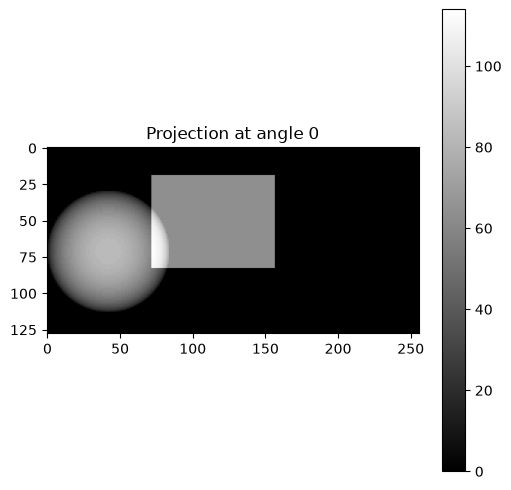

In [4]:
import matplotlib.pyplot as plt

# get a single projection image (angle index 0) instead of the whole stack
proj_0 = di.get_projections(index=0)
print(proj_0.shape, proj_0.dtype)

plt.figure(figsize=(6, 6))
plt.imshow(proj_0, cmap="gray")
plt.title("Projection at angle 0")
plt.colorbar()
plt.show()

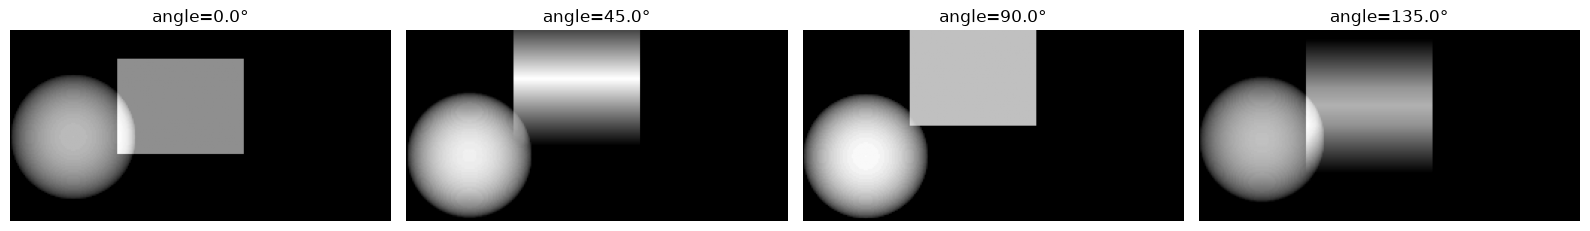

In [5]:
angles = di.get_metadata("angles")
n = len(angles)
indices = [0, n // 4, n // 2, 3 * n // 4]

fig, axes = plt.subplots(1, len(indices), figsize=(16, 4))
for ax, i in zip(axes, indices):
    ax.imshow(di.get_projections(index=i), cmap="gray")
    ax.set_title(f"angle={angles[i]:.1f}°")
    ax.axis("off")
plt.tight_layout()
plt.show()

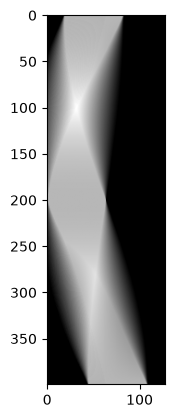

In [11]:
# plot sinograms 
all_proj = di.get_projections()  
x,y,z = all_proj.shape #(400, 128, 256)
plt.imshow(all_proj[:, :, z//2], cmap="gray")